# 02 Model Scientific Interest

Canonical modeling notebook for yearly scientific interest.
This notebook computes SI, ranks future high-interest pathogen-antibiotic pairs, and generates focused plots.
Set `ANTIBIOTIC_ANALYSIS_LEVEL` to `"antibiotic"` for individual antibiotics, or to a column in `assets/antibiotic_coarsening_lookup.csv` such as `"Class"`.


In [1]:
%load_ext autoreload
%autoreload 2


In [2]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "amr").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "amr").exists():
    raise RuntimeError(f"Could not find repository root from {Path.cwd()}")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from amr.pipelines.si import (
    build_si_analysis_paths,
    build_si_driver_analysis,
    build_yearly_si_dataset,
    load_yearly_si_inputs,
    prepare_antibiotic_analysis_level,
    rank_future_high_interest_pairs,
    save_category_driver_plots,
    save_interesting_si_plots,
    select_existing_columns,
)


## Configuration


In [3]:
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "assets").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = PROJECT_ROOT

YEARLY_SCREENED_PATH = DATA_DIR / "yearly_amr_screened_pairs.parquet"
UNIFIED_DECISIONS_PATH = DATA_DIR / "yearly_amr_unified_decisions.parquet"
PATHOGEN_BG_PATH = DATA_DIR / "pathogen_tiab_counts.parquet"
ANTIBIOTIC_BG_PATH = DATA_DIR / "antibiotic_tiab_counts.parquet"
ANTIBIOTIC_COARSENING_PATH = DATA_DIR / "assets" / "antibiotic_coarsening_lookup.csv"

ANTIBIOTIC_ANALYSIS_LEVEL = "class"
SI_PATHS = build_si_analysis_paths(DATA_DIR, ANTIBIOTIC_ANALYSIS_LEVEL)
YEARLY_SI_PATH = SI_PATHS["yearly_si"]
RANK_OUTPUT_PATH = SI_PATHS["rank_output"]
INTERESTING_OUTPUT_PATH = SI_PATHS["interesting_output"]
DRIVER_OUTPUT_PATH = SI_PATHS["driver_output"]
INTERESTING_PLOT_DIR = SI_PATHS["interesting_plot_dir"]
DRIVER_PLOT_DIR = SI_PATHS["driver_plot_dir"]

FIT_START_YEAR = 2010
FIT_END_YEAR = 2023
NUM_FUTURE_YEARS = 2

MIN_CURRENT_PREDICTED_COUNT = 1
MIN_FUTURE_PREDICTED_COUNT = 1
MIN_SI_CHANGE = 0.02
MIN_POST_FIT_OBSERVED_YEARS = 1
MAX_POST_FIT_SI_ABS_PCT_ERROR_MEAN = 750.0
FALLBACK_TOP_N = 10

CATEGORY_INCLUDE_DECISIONS = ("yes", "uncertain")
DRIVER_LOOKBACK_YEARS = 5
MAX_DRIVER_PLOTS = 25
MAX_INTERESTING_PLOTS = 25
FIGURE_FORMAT = "pdf"
DISPLAY_PLOTS = True
MAX_DISPLAY_PLOTS = 10


## Load Canonical Inputs


In [4]:
yearly_screened_df, pathogen_bg_df, antibiotic_bg_df, unified_decisions_df = load_yearly_si_inputs(
    yearly_screened_path=YEARLY_SCREENED_PATH,
    pathogen_background_path=PATHOGEN_BG_PATH,
    antibiotic_background_path=ANTIBIOTIC_BG_PATH,
    unified_decisions_path=UNIFIED_DECISIONS_PATH,
)


yearly_screened rows: 234
pathogen bg rows: 79
antibiotic bg rows: 85
unified decision rows available for driver analysis: 2,720


## Prepare Antibiotic Analysis Level

This step optionally aggregates from individual antibiotics to a selected coarsening column before SI modeling.


In [5]:
yearly_screened_model_df, antibiotic_bg_model_df, unified_decisions_model_df, analysis_summary = prepare_antibiotic_analysis_level(
    yearly_screened_df=yearly_screened_df,
    antibiotic_background_df=antibiotic_bg_df,
    unified_decisions_df=unified_decisions_df,
    coarsening_path=ANTIBIOTIC_COARSENING_PATH,
    analysis_level=ANTIBIOTIC_ANALYSIS_LEVEL,
)

yearly_screened_model_df.head(10)


Antibiotic analysis level: 'Class'. Mapped 245 antibiotics into 38 groups.
AMR yearly mapping coverage: 100.00%
Antibiotic background mapping coverage: 100.00%
Unified decision mapping coverage: 100.00%
model yearly rows: 157
model pathogen-antibiotic rows: 14
model antibiotic values: 3
model antibiotic background rows: 51
model unified decision rows: 2,470


,pathogen,antibiotic,year,pmids,count
0,Clostridioides difficile,Beta-lactam/beta-lactamase-inhibitor,2010,[19406247],1
1,Clostridioides difficile,Beta-lactam/beta-lactamase-inhibitor,2012,[23072056],1
2,Clostridioides difficile,Beta-lactam/beta-lactamase-inhibitor,2014,[24320797],1
3,Clostridioides difficile,Beta-lactam/beta-lactamase-inhibitor,2015,[24875330],1
4,Clostridioides difficile,Beta-lactam/beta-lactamase-inhibitor,2016,[27536994],1
5,Clostridioides difficile,Beta-lactam/beta-lactamase-inhibitor,2017,[29151897],1
6,Clostridioides difficile,Beta-lactam/beta-lactamase-inhibitor,2018,[29802886],1
7,Clostridioides difficile,Penicillins,2010,"[19406247, 20518764, 20890081]",3
8,Clostridioides difficile,Penicillins,2012,"[22710106, 23001653, 23072056]",3
9,Clostridioides difficile,Penicillins,2014,"[24320797, 25006233, 25247417]",3


## Build Yearly SI Dataset


In the next code cell, the notebook combines the screened yearly AMR counts with background publication counts to calculate a scientific-interest score for each pathogen-antibiotic-year. In simple terms, it estimates how much attention each pair is getting beyond what would be expected from general research activity alone, then saves those results for ranking and forecasting in later steps.


In [6]:
si_df, pooled_model, design_columns = build_yearly_si_dataset(
    yearly_screened_model_df,
    pathogen_bg_df,
    antibiotic_bg_model_df,
    output_path=YEARLY_SI_PATH,
)

print(f"SI rows: {len(si_df):,}")
print(f"SI pairs: {si_df[['pathogen','antibiotic']].drop_duplicates().shape[0]:,}")
si_df.head(10)


SI rows: 157
SI pairs: 14


,pathogen,antibiotic,year,pmids,count,bg_pathogen_n,bg_antibiotic_n,log_count,log_bg_pathogen_n,log_bg_antibiotic_n,expected_log_count_global,expected_count_global,SI
0,Clostridioides difficile,Beta-lactam/beta-lactamase-inhibitor,2010,[19406247],1,522,148,0.30103,2.718502,2.173186,-0.036070,0.000000,0.337100
1,Clostridioides difficile,Beta-lactam/beta-lactamase-inhibitor,2012,[23072056],1,714,169,0.30103,2.854306,2.230449,0.062383,0.154472,0.238647
2,Clostridioides difficile,Beta-lactam/beta-lactamase-inhibitor,2014,[24320797],1,951,180,0.30103,2.978637,2.257679,0.140699,0.382607,0.160331
3,Clostridioides difficile,Beta-lactam/beta-lactamase-inhibitor,2015,[24875330],1,1030,231,0.30103,3.013259,2.365488,0.209527,0.620046,0.091503
4,Clostridioides difficile,Beta-lactam/beta-lactamase-inhibitor,2016,[27536994],1,1070,236,0.30103,3.029789,2.374748,0.222586,0.669499,0.078444
5,Clostridioides difficile,Beta-lactam/beta-lactamase-inhibitor,2017,[29151897],1,1030,250,0.30103,3.013259,2.399674,0.225565,0.680991,0.075465
6,Clostridioides difficile,Beta-lactam/beta-lactamase-inhibitor,2018,[29802886],1,1141,241,0.30103,3.057666,2.383815,0.241535,0.743954,0.059495
7,Clostridioides difficile,Penicillins,2010,"[19406247, 20518764, 20890081]",3,522,1037,0.60206,2.718502,3.016197,0.500208,2.163791,0.101852
8,Clostridioides difficile,Penicillins,2012,"[22710106, 23001653, 23072056]",3,714,1172,0.60206,2.854306,3.069298,0.596709,2.951013,0.005351
9,Clostridioides difficile,Penicillins,2014,"[24320797, 25006233, 25247417]",3,951,1357,0.60206,2.978637,3.132900,0.692088,3.921387,-0.090028


## Rank Reliable Future High-Interest Pairs


In [7]:
rank_df, interesting_df = rank_future_high_interest_pairs(
    si_df,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    min_current_predicted_count=MIN_CURRENT_PREDICTED_COUNT,
    min_future_predicted_count=MIN_FUTURE_PREDICTED_COUNT,
    min_si_change=MIN_SI_CHANGE,
    min_post_fit_observed_years=MIN_POST_FIT_OBSERVED_YEARS,
    max_post_fit_si_abs_pct_error_mean=MAX_POST_FIT_SI_ABS_PCT_ERROR_MEAN,
    fallback_top_n=FALLBACK_TOP_N,
    rank_output_path=RANK_OUTPUT_PATH,
    interesting_output_path=INTERESTING_OUTPUT_PATH,
    verbose=True,
)

select_existing_columns(
    interesting_df,
    [
        "pathogen",
        "antibiotic",
        "interest_score",
        "si_change",
        "current_predicted_count",
        "future_predicted_count",
        "post_fit_si_abs_pct_error_mean",
    ],
    head=30,
)


[1/14] ranking Clostridioides difficile vs Beta-lactam/beta-lactamase-inhibitor


[2/14] ranking Clostridioides difficile vs Penicillins


[3/14] ranking Haemophilus influenzae vs Aminoglycosides


[4/14] ranking Haemophilus influenzae vs Beta-lactam/beta-lactamase-inhibitor


[5/14] ranking Haemophilus influenzae vs Penicillins


...

[11/14] ranking Mycobacterium tuberculosis vs Penicillins


[12/14] ranking Salmonella enterica vs Aminoglycosides


[13/14] ranking Salmonella enterica vs Beta-lactam/beta-lactamase-inhibitor


[14/14] ranking Salmonella enterica vs Penicillins


,pathogen,antibiotic,interest_score,si_change,current_predicted_count,future_predicted_count,post_fit_si_abs_pct_error_mean
0,Klebsiella pneumoniae,Beta-lactam/beta-lactamase-inhibitor,0.036157,0.083953,27.371431,46.764880,397.728339
1,Klebsiella pneumoniae,Penicillins,0.025979,0.052660,77.692037,118.375488,375.524057
2,Haemophilus influenzae,Penicillins,0.019323,0.035476,14.775680,16.118451,NaN
3,Salmonella enterica,Beta-lactam/beta-lactamase-inhibitor,0.013866,0.032645,6.847647,9.573513,213.921660


## Explain Predicted SI Changes

This section uses the LLM category metadata from the unified abstract screen to describe which AMR paper types are driving the observed count curves behind the SI forecast. The analysis is descriptive: it explains category mix and recent changes, while the ranking itself remains based on the screened yearly AMR counts.


In [8]:
category_counts_df, interesting_with_drivers_df = build_si_driver_analysis(
    interesting_df=interesting_df,
    unified_decisions_df=unified_decisions_model_df,
    fit_end_year=FIT_END_YEAR,
    include_decisions=CATEGORY_INCLUDE_DECISIONS,
    lookback_years=DRIVER_LOOKBACK_YEARS,
    output_path=DRIVER_OUTPUT_PATH,
)

select_existing_columns(
    interesting_with_drivers_df,
    [
        "pathogen",
        "antibiotic",
        "interest_score",
        "si_change",
        "current_predicted_count",
        "future_predicted_count",
        "driver_recent_total",
        "driver_count_change",
        "driver_dominant_category",
        "driver_fastest_growing_category",
        "driver_weak_signal_share",
        "driver_manual_review_share",
    ],
    head=30,
)


Saved SI driver explanations to /media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/yearly_si_driver_explanations_class.parquet


,pathogen,antibiotic,interest_score,si_change,current_predicted_count,future_predicted_count,driver_recent_total,driver_count_change,driver_dominant_category,driver_fastest_growing_category,driver_weak_signal_share,driver_manual_review_share
0,Klebsiella pneumoniae,Beta-lactam/beta-lactamase-inhibitor,0.036157,0.083953,27.371431,46.764880,85,49,RESISTANCE_PREVALENCE_SURVEILLANCE,RESISTANCE_PREVALENCE_SURVEILLANCE,0.0,0.694118
1,Klebsiella pneumoniae,Penicillins,0.025979,0.052660,77.692037,118.375488,269,170,RESISTANCE_PREVALENCE_SURVEILLANCE,RESISTANCE_PREVALENCE_SURVEILLANCE,0.0,0.817844
2,Haemophilus influenzae,Penicillins,0.019323,0.035476,14.775680,16.118451,14,-41,RESISTANCE_PREVALENCE_SURVEILLANCE,TREATMENT_EFFECTIVENESS,0.0,0.714286
3,Salmonella enterica,Beta-lactam/beta-lactamase-inhibitor,0.013866,0.032645,6.847647,9.573513,27,1,RESISTANCE_PREVALENCE_SURVEILLANCE,ONE_HEALTH_ENVIRONMENTAL_RESERVOIR,0.0,0.888889


## Plot Category Driver Curves


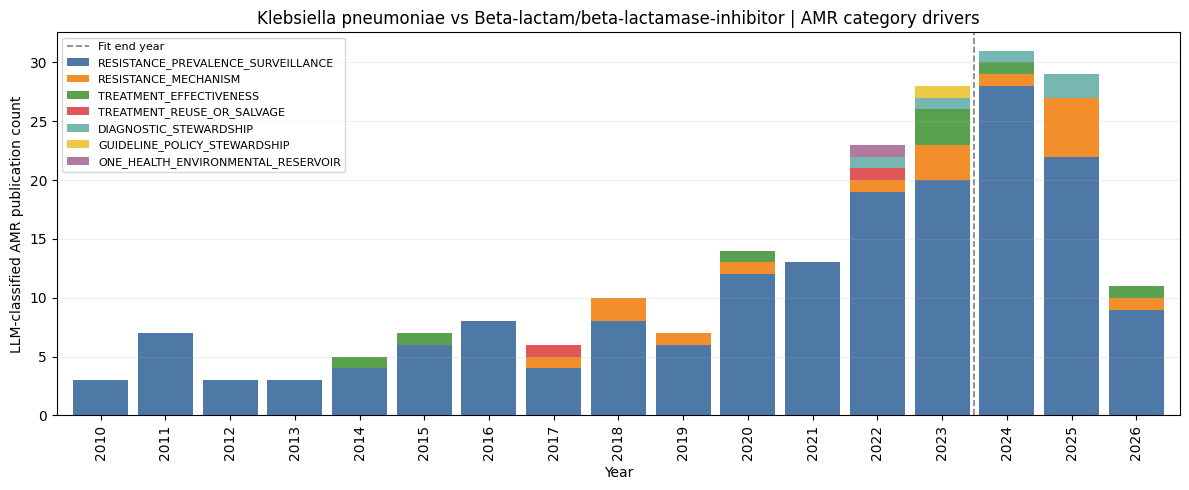

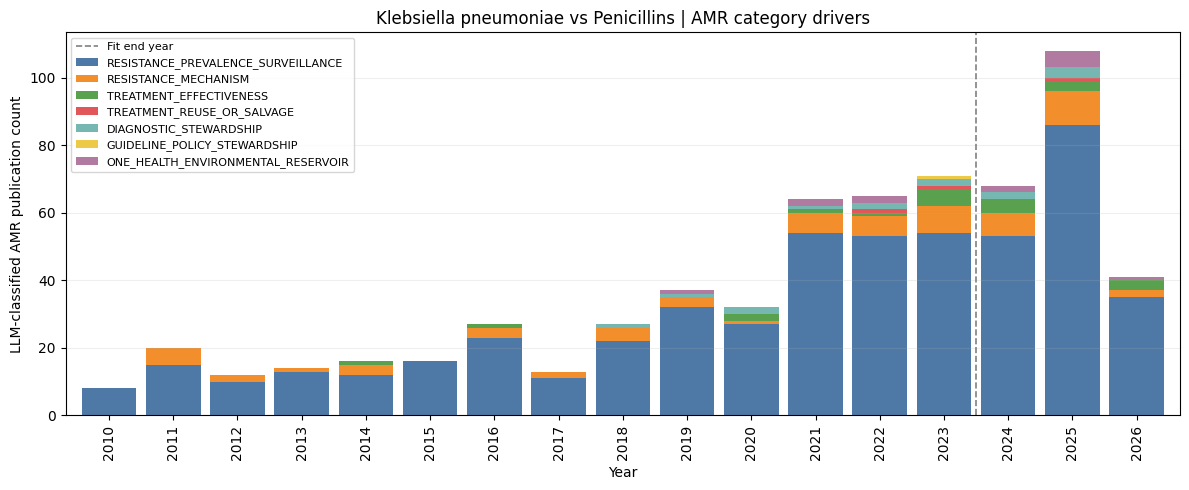

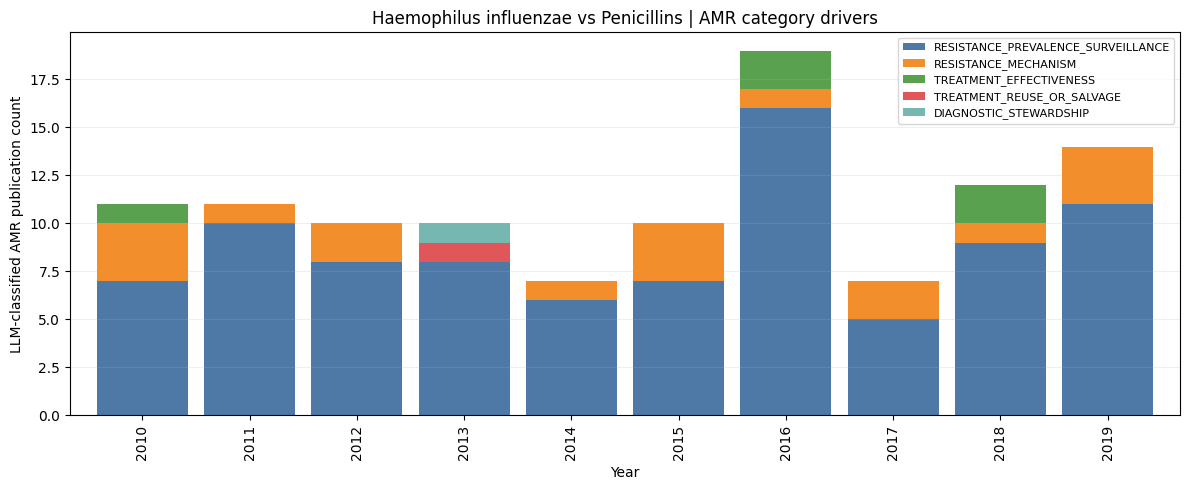

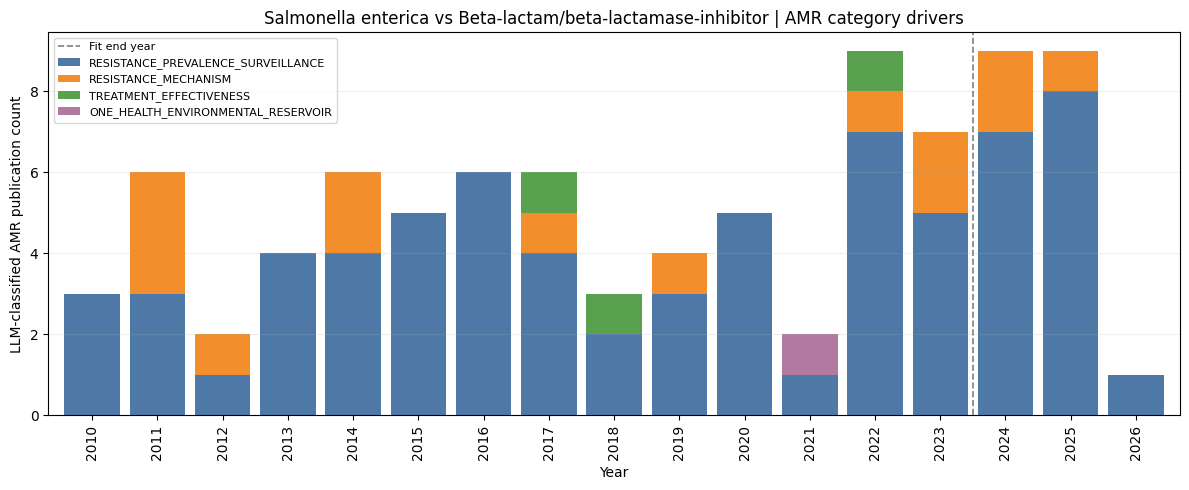

Saved 4 category driver plots to /media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/figures/interesting_yearly_si_driver_plots_class
Displayed 4 category driver plots inline.


In [9]:
saved_driver_plots = save_category_driver_plots(
    category_counts_df=category_counts_df,
    interesting_df=interesting_df,
    output_dir=DRIVER_PLOT_DIR,
    fit_end_year=FIT_END_YEAR,
    max_plots=MAX_DRIVER_PLOTS,
    figure_format=FIGURE_FORMAT,
    display_plots=DISPLAY_PLOTS,
    max_display_plots=MAX_DISPLAY_PLOTS,
)


## Plot Top Interesting Pairs


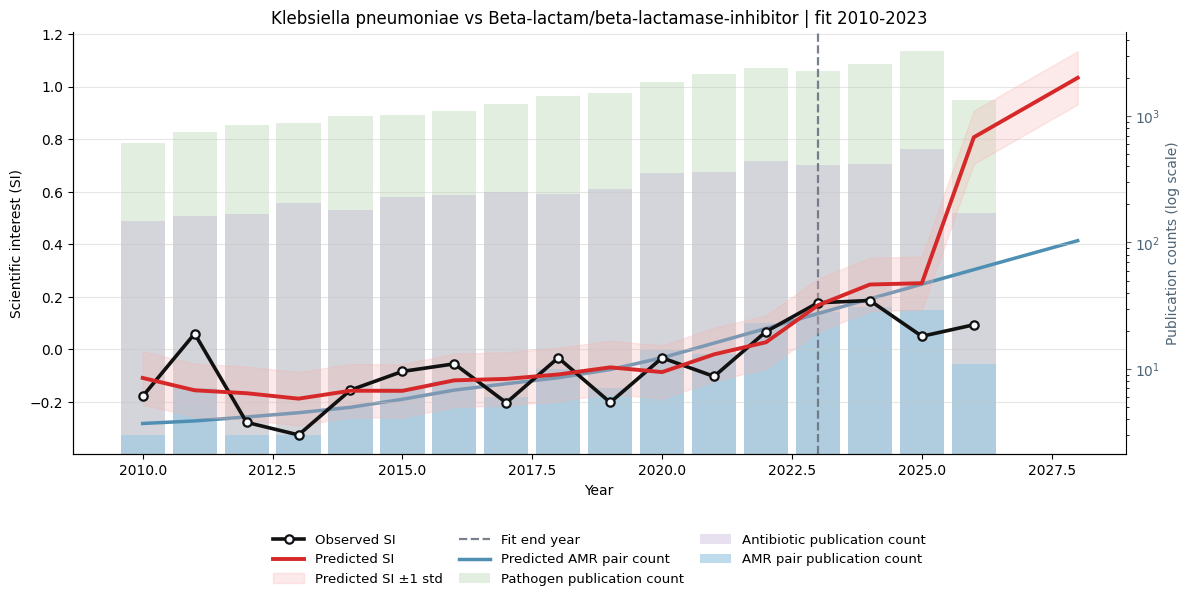

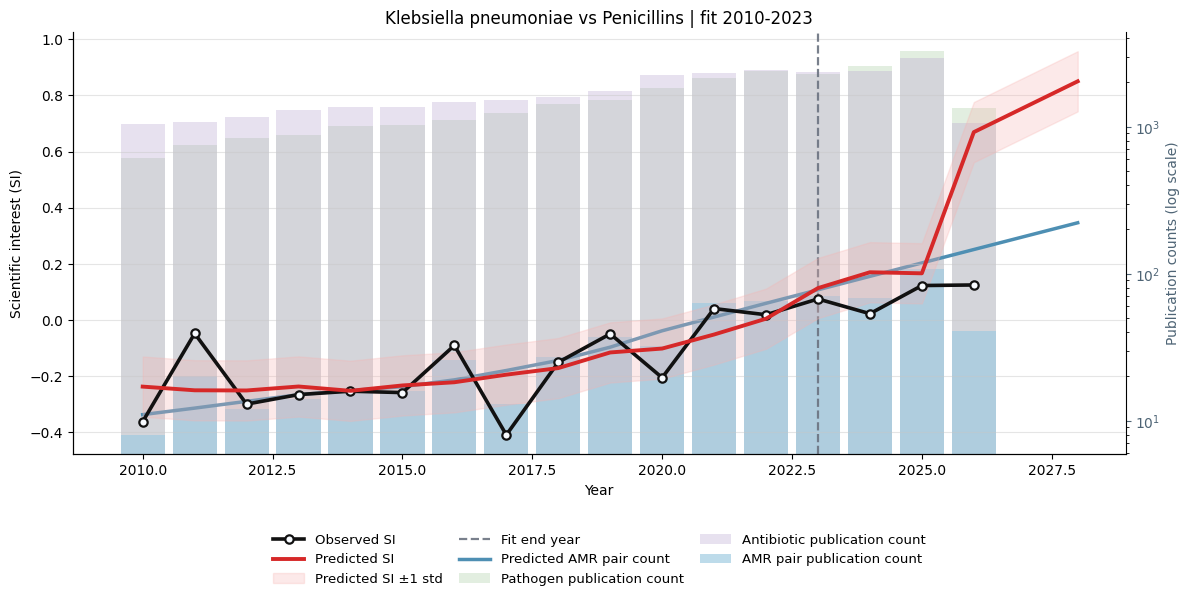

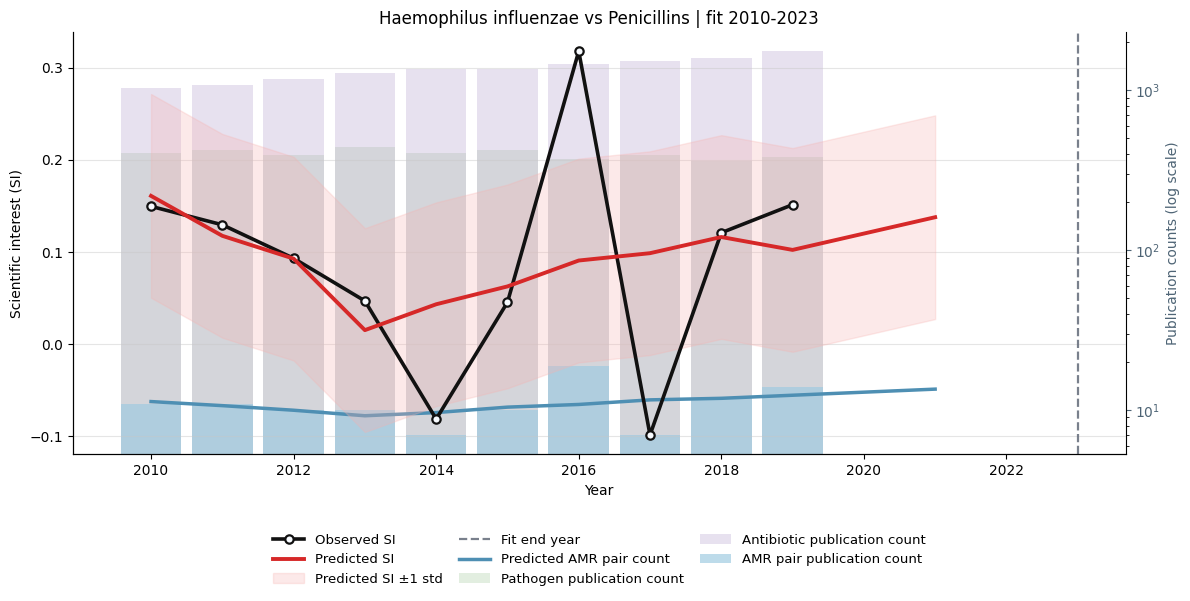

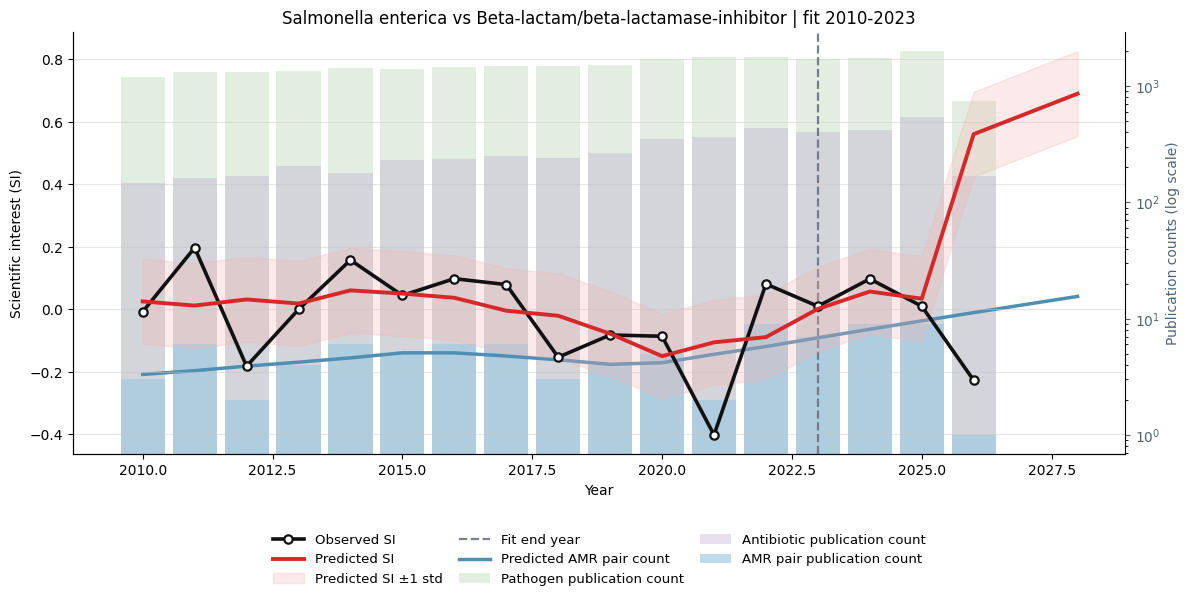

Saved 4 plots to /media/fabrizio/06bb7271-2161-43a4-91f1-98f9b67e9ab2/home/fabrizio/code/Antimicrobial-Resistance/figures/interesting_yearly_si_plots_class
Displayed 4 plots inline.


In [10]:
saved_interesting_plots = save_interesting_si_plots(
    si_df=si_df,
    interesting_df=interesting_df,
    output_dir=INTERESTING_PLOT_DIR,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    max_plots=MAX_INTERESTING_PLOTS,
    loess_frac=0.6,
    loess_degree=1,
    tail_damping_years=None,
    figure_format=FIGURE_FORMAT,
    display_plots=DISPLAY_PLOTS,
    max_display_plots=MAX_DISPLAY_PLOTS,
)
